平衡过程:
  RED: 291 → 214 (随机抽样)
  GEMV: 356 → 214 (随机抽样)
  BS: 244 → 214 (随机抽样)
  VA: 348 → 214 (随机抽样)
  HST-S: 422 → 214 (随机抽样)
  TS: 740 → 214 (随机抽样)
  MLP: 777 → 214 (随机抽样)
  SEL: 214 → 214 (保持不变)
  NW: 967 → 214 (随机抽样)
  BFS: 248 → 214 (随机抽样)
RED      291        214        7.28       7.29       0.010   
GEMV     356        214        7.18       7.25       0.076   
BS       244        214        7.22       7.25       0.027   
VA       348        214        7.14       7.23       0.090   
HST-S    422        214        7.15       7.26       0.111   
TS       740        214        6.97       6.95       0.018   
MLP      777        214        6.96       6.99       0.022   
SEL      214        214        12.52      12.52      0.000   
NW       967        214        4.16       4.17       0.013   
BFS      248        214        4.32       4.35       0.031   


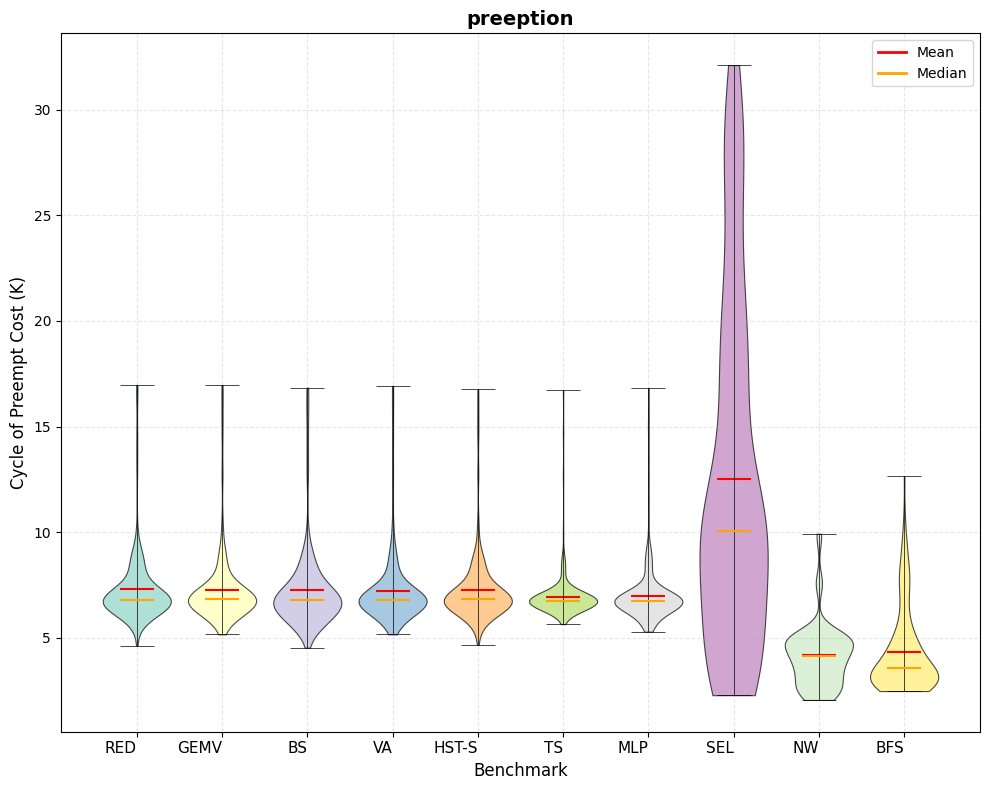

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from io import StringIO
from matplotlib.lines import Line2D
def balance_preempt_data(df):
    """
    平衡不同code的preempt数据量
    
    什么是平衡？
    - 问题：不同的baseline可能有不同数量的测试数据
      例如：RED有150个测试结果，GEMV有700个测试结果
    - 影响：数据量多的baseline在可视化中会显得"更重要"，影响公平比较
    - 解决：将所有baseline的数据量统一到最少的那个数量
      例如：如果最少的有150个，就把所有超过150个的都随机抽样到150个
    - 好处：确保每个baseline在比较中有相同的"权重"
    """
    
    # 获取preempt列
    preempt_columns = [col for col in df.columns if col.startswith('preempt_')]
    
    balanced_data = {}
    actual_data_counts = {}
    
    # 统计每个code的实际数据点数
    for idx, row in df.iterrows():
        code = row['code']
        preempt_values = row[preempt_columns].values
        
        # 移除NaN值（如果有的话）
        valid_values = preempt_values[~pd.isna(preempt_values)]
        actual_data_counts[code] = len(valid_values)
        balanced_data[code] = valid_values.tolist()
    
    # 找到最小数据点数
    min_actual_points = min(actual_data_counts.values())
    
    
    # 对超过最小数量的code进行抽样
    balanced_final = {}
    
    print("平衡过程:")
    for code, values in balanced_data.items():
        if len(values) > min_actual_points:
            # 进行随机抽样
            np.random.seed(42)  # 设置随机种子确保可重复性
            sampled_indices = np.random.choice(len(values), min_actual_points, replace=False)
            balanced_final[code] = [values[i] for i in sorted(sampled_indices)]
            print(f"  {code}: {len(values):3d} → {len(balanced_final[code]):3d} (随机抽样)")
        else:
            balanced_final[code] = values
            print(f"  {code}: {len(values):3d} → {len(values):3d} (保持不变)")
    
    return balanced_final, min_actual_points

def create_balanced_violin_plot(data_source):
    """
    创建数据量平衡的小提琴图
    """
    
    # 读取数据
    if data_source.endswith('.csv'):
        df = pd.read_csv(data_source)
    else:
        df = pd.read_csv(StringIO(data_source))
    
  
    
    # 将所有preempt数据按1000取整
    preempt_columns = [col for col in df.columns if col.startswith('preempt_')]
    df[preempt_columns] = df[preempt_columns] / 1000
    
   
    
    # 平衡数据
    balanced_data, min_points = balance_preempt_data(df)
    
    # 设置中文字体
    plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans', 'Arial Unicode MS']
    plt.rcParams['axes.unicode_minus'] = False
    
    # 创建图形 - 只显示小提琴图
    fig, ax2 = plt.subplots(1, 1, figsize=(10, 8))
    
    # 准备数据
    codes = list(balanced_data.keys())
    original_data = []  # 取整后但未平衡的数据
    balanced_data_list = []  # 平衡后的数据
    
    for code in codes:
        # 原始取整数据（未平衡）
        original_values = df[df['code'] == code][preempt_columns].values[0]
        original_values = original_values[~pd.isna(original_values)]  # 移除NaN
        original_data.append(original_values.tolist())
        
        # 平衡后的数据
        balanced_data_list.append(balanced_data[code])
    
    # 颜色设置
    colors = plt.cm.Set3(np.linspace(0, 1, len(codes)))
    
    # 1. 原始数据小提琴图（取整后，未平衡）
    # violin_parts1 = ax1.violinplot(original_data, 
    #                                positions=range(1, len(codes) + 1),
    #                                showmeans=True,
    #                                showmedians=True,
    #                                showextrema=True,
    #                                widths=0.8)
    
    # for i, pc in enumerate(violin_parts1['bodies']):
    #     pc.set_facecolor(colors[i])
    #     pc.set_alpha(0.7)
    #     pc.set_edgecolor('black')
    #     pc.set_linewidth(0.8)
    
    # # 设置小提琴图元素颜色
    # violin_parts1['cmeans'].set_color('red')
    # violin_parts1['cmedians'].set_color('orange')
    # violin_parts1['cbars'].set_color('black')
    # violin_parts1['cmins'].set_color('black')
    # violin_parts1['cmaxes'].set_color('black')
    
    # ax2.set_title(f'preeption', fontsize=14, fontweight='bold')
    # ax2.set_xticks(range(1, len(codes) + 1))
    # ax2.set_xticklabels(codes, rotation=45, ha='right', fontsize=11)
    # ax2.set_xlabel('Benchmark', fontsize=12)
    # ax2.set_ylabel('Cycle of Preempt Cost (K)', fontsize=12)
    # ax2.grid(True, alpha=0.3, linestyle='--')
    
  
    
    # 2. 平衡后数据小提琴图
    violin_parts2 = ax2.violinplot(balanced_data_list, 
                                   positions=range(1, len(codes) + 1),
                                   showmeans=True,
                                   showmedians=True,
                                   showextrema=True,
                                   widths=0.8)
    
    for i, pc in enumerate(violin_parts2['bodies']):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        pc.set_edgecolor('black')
        pc.set_linewidth(0.8)
    
    violin_parts2['cmeans'].set_color('red')
    violin_parts2['cmedians'].set_color('orange')
    violin_parts2['cbars'].set_color('black')
    violin_parts2['cmins'].set_color('black')
    violin_parts2['cmaxes'].set_color('black')
    violin_parts2['cbars'].set_linewidth(0.5)    # 中间的横线
    violin_parts2['cmins'].set_linewidth(0.5)    # 最小值的线
    violin_parts2['cmaxes'].set_linewidth(0.5)   # 最大值的线
    
    ax2.set_title(f'preeption', fontsize=14, fontweight='bold')
    ax2.set_xticks(range(1, len(codes) + 1))
    ax2.set_xticklabels(codes, rotation=0, ha='right', fontsize=11)
    ax2.set_xlabel('Benchmark', fontsize=12)
    ax2.set_ylabel('Cycle of Preempt Cost (K)', fontsize=12)
    ax2.grid(True, alpha=0.3, linestyle='--')
    legend_elements = [
        Line2D([0], [0], color='red', lw=2, label='Mean'),
        Line2D([0], [0], color='orange', lw=2, label='Median')
    ]
    ax2.legend(handles=legend_elements, loc='upper right', fontsize=10)

    
    # # 添加统一的数据点数量标注
    # for i in range(len(codes)):
    #     ax2.text(i+1, ax2.get_ylim()[1], f'n={min_points}', 
    #             ha='center', va='bottom', fontsize=9,
    #             bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgreen', alpha=0.7))
    
    plt.tight_layout()
    
    # 统计分析对比

    
    for i, code in enumerate(codes):
        orig_values = np.array(original_data[i])
        balanced_values = np.array(balanced_data_list[i])
        
        orig_mean = orig_values.mean()
        balanced_mean = balanced_values.mean()
        diff = abs(orig_mean - balanced_mean)
        
        print(f"{code:<8} {len(orig_values):<10} {len(balanced_values):<10} "
              f"{orig_mean:<10.2f} {balanced_mean:<10.2f} {diff:<8.3f}")
    
  
    plt.show()
    #保存图片
    fig.savefig('preempt.png', dpi=300, bbox_inches='tight')
    
    return df, balanced_data

# 运行分析
if __name__ == "__main__":
    # 使用CSV文件
    df, balanced_data = create_balanced_violin_plot('preempt.csv')